## Import the Libraries

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load the data

In [38]:
# load the data
path_1 = "C:/Users/HomePC/Downloads/Copy of FinTrust_Customer_Data.csv"
path_2 = "C:/Users/HomePC/Downloads/FinTrust_Transaction_Clean.csv"
cust_data = pd.read_csv(path_1)
trans_data = pd.read_csv(path_2)      


In [3]:
# verify the customer data
cust_data.head()

,Customer_ID,Customer_Name,Age,Gender,City,Customer_Segment,Account_Type,Tenure_Months,Digital_Engagement_Score,Monthly_Income_Band,Preferred_Channel,Account_Status,age_group
0,FT-C00001,Ibrahim Adeyemi,56,Male,Lagos,Premium,Savings,55,84.9,500k-999k,Mobile App,Active,55+
1,FT-C00002,Yusuf Mohammed,46,Male,Kano,Everyday,Current,79,50.7,500k-999k,Mobile App,Active,45-54
2,FT-C00003,Emeka Adeyemi,32,Female,Port Harcourt,Everyday,Savings,43,56.1,1m+,Mobile App,Active,25-34
3,FT-C00004,David Williams,60,Female,Benin City,Premium,Premium,44,54.0,500k-999k,Mobile App,Dormant,55+
4,FT-C00005,Blessing Adeyemi,25,Male,Kaduna,Premium,Savings,68,85.1,500k-999k,Mobile App,Active,25-34


In [4]:
# verify the transaction data
trans_data.head()

,Transaction_ID,Customer_ID,Transaction_DateTime,Transaction_Type,Amount_NGN,Channel,Device_Type,Location,International_Transaction,Transaction_Status,Risk_Review_Flag
0,FT-T000001,FT-C01135,1/1/2026 0:00:00,Card Purchase,5923.80,Mobile App,Android,Enugu,No,Reversed,Yes
1,FT-T000002,FT-C00428,1/1/2026 0:10:00,Cash Withdrawal,11681.12,ATM,ATM Terminal,Kaduna,No,Successful,Yes
2,FT-T000003,FT-C00469,1/1/2026 0:21:00,Transfer,571.91,POS,POS Terminal,Kano,No,Successful,No
3,FT-T000004,FT-C01015,1/1/2026 0:32:00,Deposit,105367.52,Web,Web Browser,Abuja,No,Successful,No
4,FT-T000005,FT-C00870,1/1/2026 0:43:00,Cash Withdrawal,3049.06,POS,POS Terminal,Abuja,No,Successful,No


# Question 1 

## Customer Segment: 
How is the customer base distributed across segments, and does average transaction value differ meaningfully between segments?

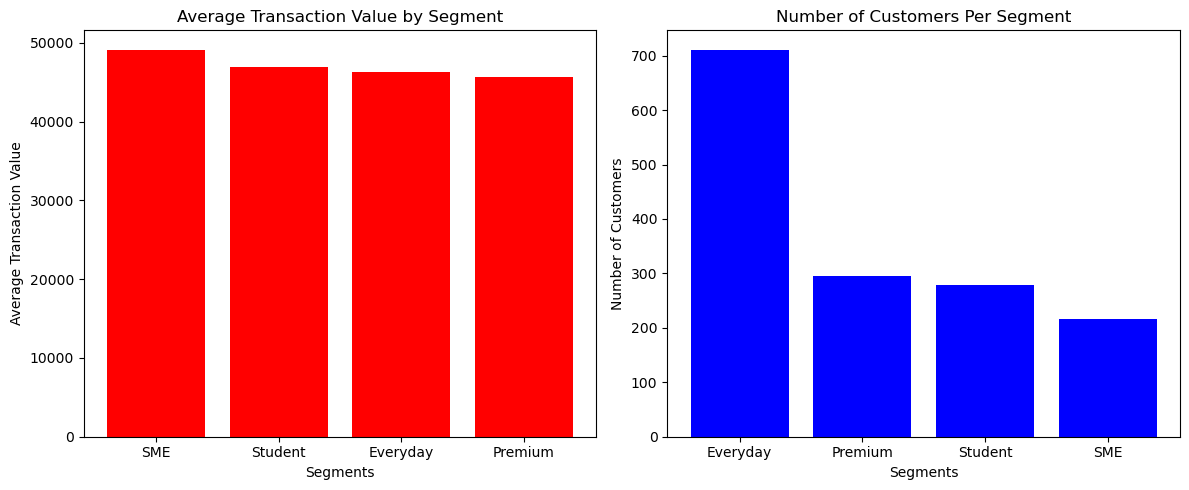

In [16]:
# Merge to bring segment info into transactions
df = trans_data.merge(cust_data, on="Customer_ID", how="left")

# Calculate average transaction value per segment
avg_trans_value_by_segment = df.groupby("Customer_Segment")["Amount_NGN"].mean().sort_values(ascending = False)

# Calculate the segments counts
segments_counts = cust_data["Customer_Segment"].value_counts()

# plot the chart
fig, axes =plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(avg_trans_value_by_segment.index,avg_trans_value_by_segment.values, color="red")
axes[0].set_title("Average Transaction Value by Segment")
axes[0].set_xlabel("Segments")
axes[0].set_ylabel("Average Transaction Value")

axes[1].bar(segments_counts.index, segments_counts.values,color="blue")
axes[1].set_title("Number of Customers Per Segment")
axes[1].set_xlabel("Segments")
axes[1].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()


# Question 2

## Transaction Channel
How does transaction volume compare across the different channels


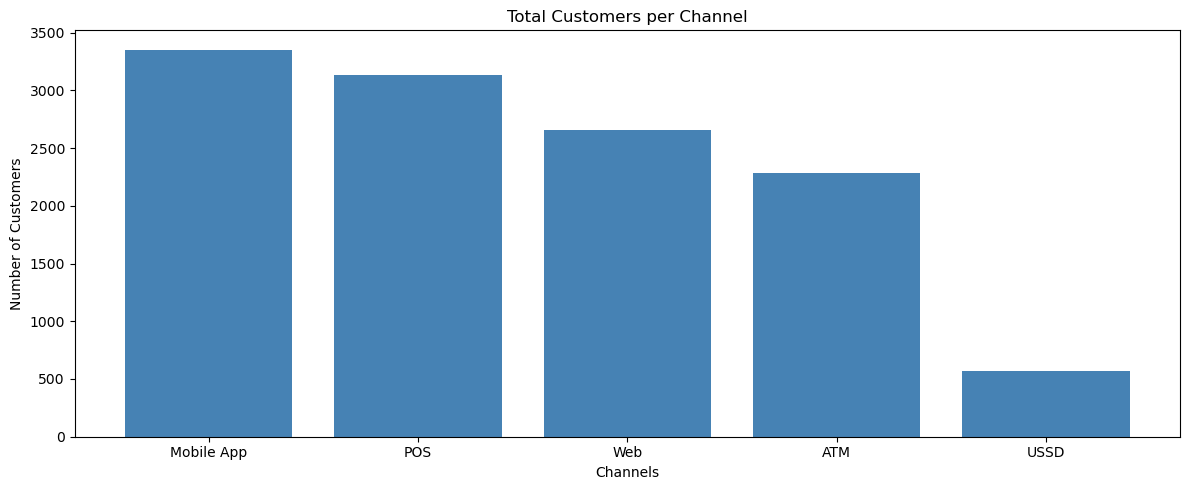

In [18]:
fig = plt.subplots(figsize = (12,5))

Channel_counts = trans_data["Channel"].value_counts()

plt.bar(Channel_counts.index, Channel_counts.values,color = "steelblue")
plt.title("Total Customers per Channel")
plt.ylabel("Number of Customers")
plt.xlabel("Channels")

plt.tight_layout()
plt.show()

# Question 3

## Transaction Status
How many transactions succeed, fail, or stay pending?

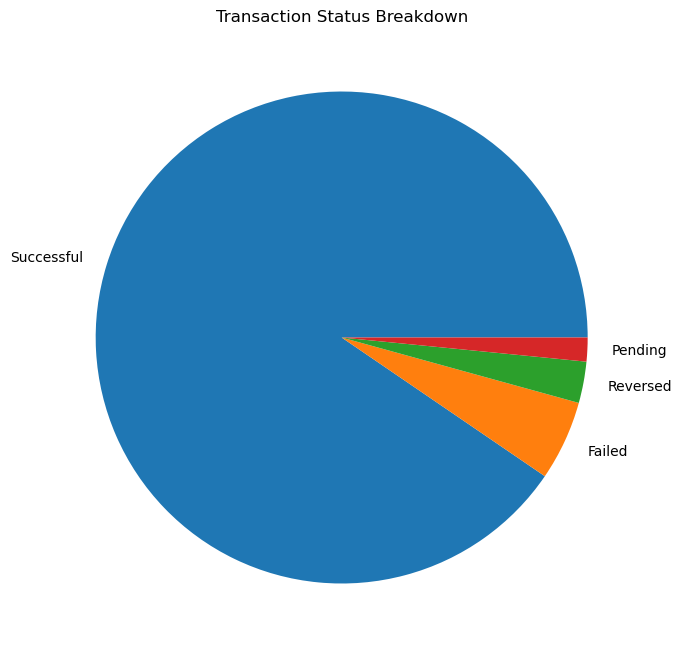

In [20]:
# Count transactions by status
status_counts = trans_data["Transaction_Status"].value_counts()

# Pie chart
plt.figure(figsize=(7, 7))
plt.pie(
    status_counts.values,
    labels=status_counts.index
)
plt.title("Transaction Status Breakdown")
plt.tight_layout()
plt.show()

# Question 4

## Transaction Amounts
Are most transactions small amounts, or are there a few very large ones mixed in?

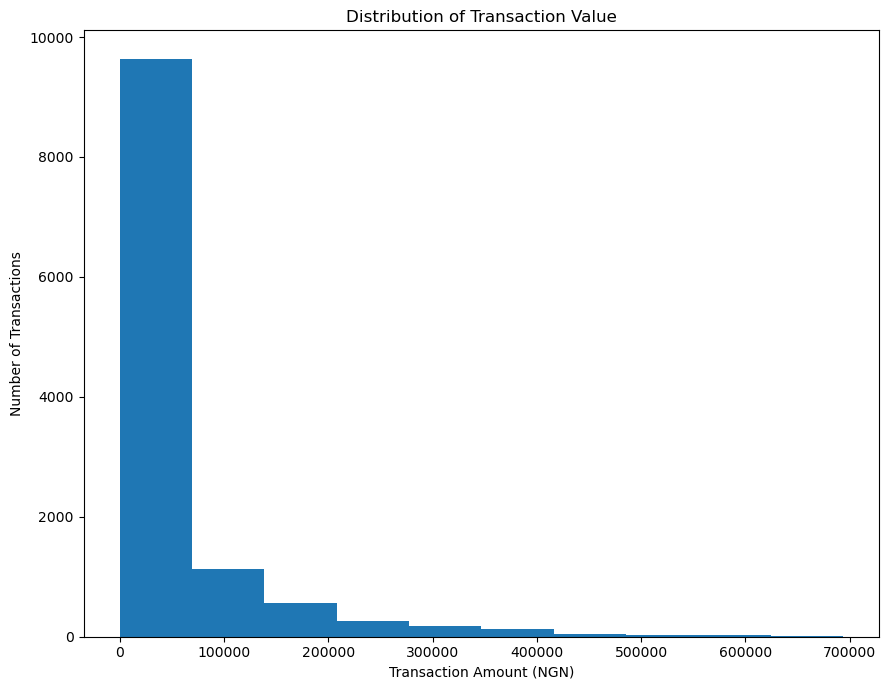

In [25]:
fig, ax = plt.subplots(figsize=(9,7))

ax.hist(trans_data["Amount_NGN"])
ax.set_title("Distribution of Transaction Value")
ax.set_xlabel("Transaction Amount (NGN)")
ax.set_ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

# Question 5

## Risk Review
Is there a relationship between transaction amount and the likelihood of a transaction being flagged for risk review — do larger transactions get flagged more often?

Correlation between Transaction Amount and Risk Flag: 0.127


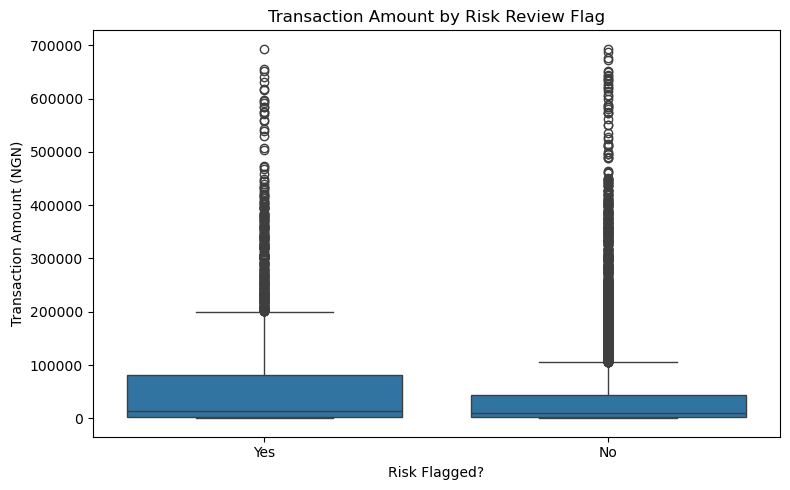

In [28]:
# Convert Risk_Review_Flag into numeric (1 = flagged, 0 = not flagged)
trans_data["Risk_Flag_Numeric"] = (trans_data["Risk_Review_Flag"] == "Yes").astype(int)

# Calculate correlation
correlation = trans_data["Amount_NGN"].corr(trans_data["Risk_Flag_Numeric"])
print(f"Correlation between Transaction Amount and Risk Flag: {correlation:.3f}")

# Box plot: compares amount distribution for flagged vs non-flagged transactions
plt.figure(figsize=(8, 5))
sns.boxplot(data=trans_data, x="Risk_Review_Flag", y="Amount_NGN")

plt.title("Transaction Amount by Risk Review Flag")
plt.xlabel("Risk Flagged?")
plt.ylabel("Transaction Amount (NGN)")

plt.tight_layout()
plt.show()

# Question 6
How does transaction volume vary by month, and is there a clear peak period?

In [20]:
# convert the datetime field to its data type

trans_data['Transaction_DateTime'] = pd.to_datetime(trans_data['Transaction_DateTime'])

In [21]:
# Extract the month name

trans_data['Month'] = trans_data['Transaction_DateTime'].dt.month_name()

In [22]:
# Count the monthly transactions

transactions_by_month = trans_data['Month'].value_counts()
print(transactions_by_month)

Month
January     4133
March       4133
February    3734
Name: count, dtype: int64


# Question 7
How does the average transaction amount compare between customers aged under 30 versus those aged 30 and above?

In [24]:
# Merge the dataset 

merged_data = trans_data.merge(
            cust_data[['Customer_ID','Age']],
            on = 'Customer_ID',
            how = 'left'
)

In [25]:
merged_data['Age_group'] = merged_data['Age'].apply(lambda x:'Under 30' if x < 30 else '30 and above')
                                            

In [26]:
average_transaction = (
    merged_data.groupby('Age_group')['Amount_NGN']
    .mean()
    .round(2)
    .reset_index()
)
average_transaction

,Age_group,Amount_NGN
0,30 and above,46493.86
1,Under 30,47335.23


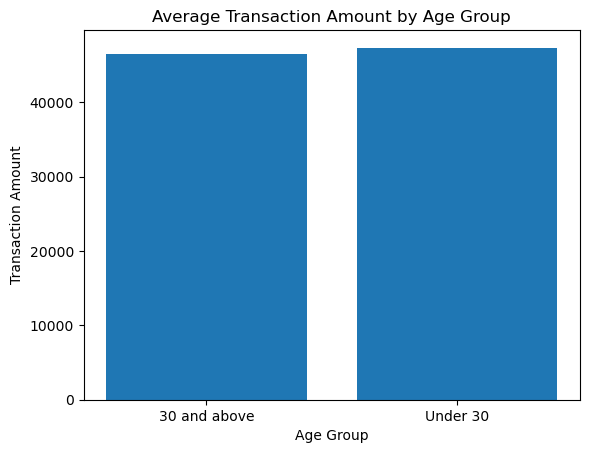

In [27]:
# plot the data

fig, ax = plt.subplots()

ax.bar(average_transaction['Age_group'], average_transaction['Amount_NGN'])

ax.set_xlabel('Age Group')
ax.set_ylabel('Transaction Amount')
ax.set_title('Average Transaction Amount by Age Group')

plt.show()

# Question 8
How does transaction amount vary across combinations of channel and transaction type — are certain pairings (e.g. ATM + Withdrawal) associated with notably higher or lower amounts?

In [34]:
transaction_behaviour = (
    trans_data.groupby(['Channel','Transaction_Type'])['Amount_NGN']
    .sum()
    .round(2)
    .reset_index()
)
transaction_behaviour

,Channel,Transaction_Type,Amount_NGN
0,ATM,Airtime/Data,1803636.76
1,ATM,Bill Payment,5758125.44
2,ATM,Card Purchase,16524969.00
3,ATM,Cash Withdrawal,11038352.50
4,ATM,Deposit,26265710.15
5,ATM,Transfer,47830832.17
6,Mobile App,Airtime/Data,2569309.54
7,Mobile App,Bill Payment,7713816.98
8,Mobile App,Card Purchase,23992828.48
9,Mobile App,Cash Withdrawal,20068251.24


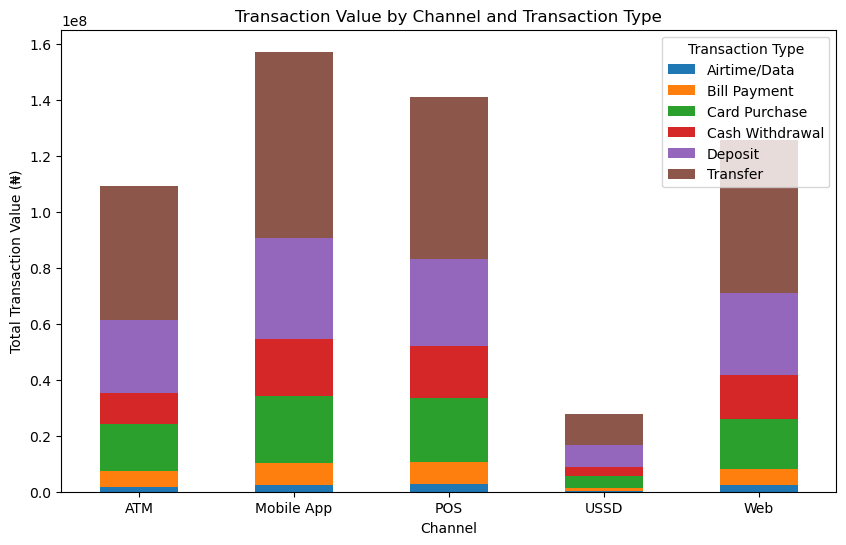

In [36]:
# plot the data

pivot_data = transaction_behaviour.pivot(
    index = 'Channel',
    columns ='Transaction_Type',
    values = 'Amount_NGN'
)

pivot_data.plot(kind='bar', stacked = True, figsize=(10, 6))

plt.title('Transaction Value by Channel and Transaction Type')
plt.xlabel('Channel')
plt.ylabel('Total Transaction Value (₦)')
plt.xticks(rotation=0)
plt.legend(title='Transaction Type')
plt.show()

# Question 9
What does the transaction amount distribution look like after removing outliers?

In [43]:
# calculate the IQR bounds

Q1 = trans_data['Amount_NGN'].quantile(0.25)
Q3 = trans_data['Amount_NGN'].quantile(0.75)

IQR = Q3 - Q1

UPPER_BOUND = Q3 + (1.5 * IQR)
LOWER_BOUND = Q1 - (1.5 * IQR)

print(f"Q1 : {Q1} | Q3 : {Q3} | IQR : {IQR}")
print(f"Upper Bound : {UPPER_BOUND} | Lower Bound : {LOWER_BOUND}")

Q1 : 2192.22 | Q3 : 48484.475 | IQR : 46292.255
Upper Bound : 117922.85749999998 | Lower Bound : -67246.16249999999


In [46]:
# count the outliers present and get the percentage

trans_data['Is_Outlier'] = (trans_data['Amount_NGN'] > UPPER_BOUND) | (trans_data['Amount_NGN'] < LOWER_BOUND)

num_of_outliers = trans_data['Is_Outlier'].sum()
pct_outliers = 100 * num_of_outliers / len(trans_data)


print(f"\nOutliers found: {num_of_outliers} transactions ({pct_outliers:.2f}% of all transactions)")


Outliers found: 1474 transactions (12.28% of all transactions)


In [48]:
# Create the "cleaned" view (outliers excluded), without altering the original data

clean_data = trans_data.loc[~trans_data['Is_Outlier'],'Amount_NGN']
full_data = trans_data['Amount_NGN']

In [49]:
# Compare summary statistics before and after

summary = pd.DataFrame({'with_outliers': full_data.describe(),
                        'without_outliers': clean_data.describe()})
print("\nSummary statistics comparison:")
print(summary.round(2).to_string())


Summary statistics comparison:
       with_outliers  without_outliers
count       12000.00          10526.00
mean        46706.45          19983.27
std         86028.72          27228.46
min           100.17            100.17
25%          2192.22           1796.78
50%         10305.94           7032.90
75%         48484.48          27012.92
max        693454.45         117900.50


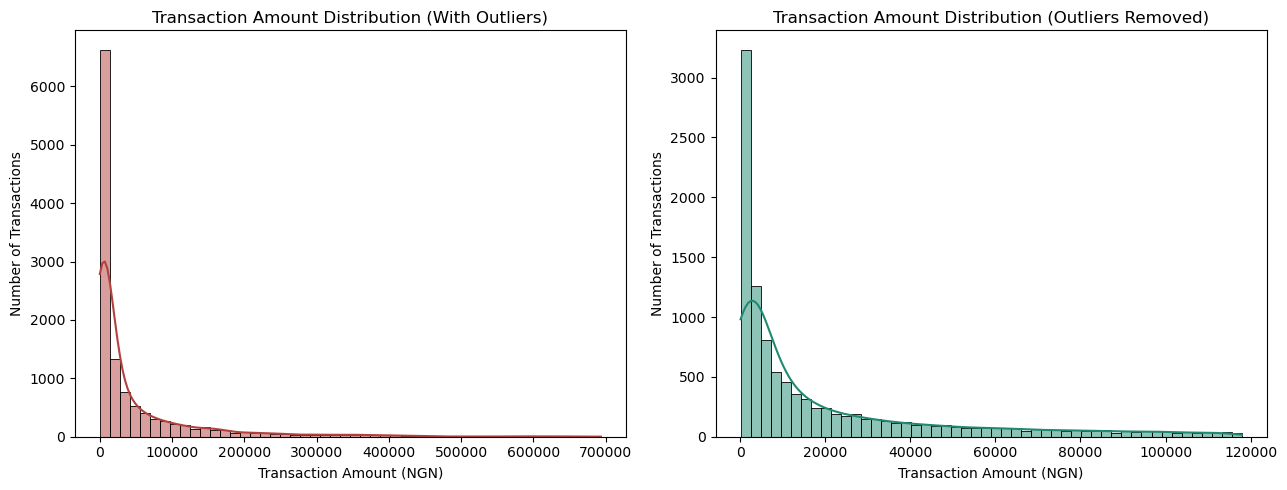

In [53]:
# Visualize both distributions side by side ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
 
sns.histplot(full_data, bins=50, color="#b3413e", kde=True, ax=axes[0])
axes[0].set_title("Transaction Amount Distribution (With Outliers)")
axes[0].set_xlabel("Transaction Amount (NGN)")
axes[0].set_ylabel("Number of Transactions")
 
sns.histplot(clean_data, bins=50, color="#1f8a70", kde=True, ax=axes[1])
axes[1].set_title("Transaction Amount Distribution (Outliers Removed)")
axes[1].set_xlabel("Transaction Amount (NGN)")
axes[1].set_ylabel("Number of Transactions")
 
plt.tight_layout()
plt.show()
 

With outliers included, the mean transaction value is ₦46,706.45, compared to a median of ₦10,305.94, a gap of roughly ₦36,400. After removing outliers, the mean drops sharply to ₦19,983.27, while the median falls to ₦7,032.90, a gap of about ₦12,950. The 1,474 outlier transactions removed (12,000 to 10,526) account for a dramatic reduction in the mean, confirming they were heavily skewing the average upward.

# Question 10
Do dormant customers show different past spending patterns than active ones?

In [59]:
# summarize each customer's transaction history

summary = (
    trans_data.groupby('Customer_ID')['Amount_NGN']
    .agg(
        total_spend = 'sum',
        avg_spend = 'mean',
        trans_freq = 'count'
    )
    .round(2)
    .reset_index()
)
summary

,Customer_ID,total_spend,avg_spend,trans_freq
0,FT-C00001,389228.44,55604.06,7
1,FT-C00002,262429.47,52485.89,5
2,FT-C00003,30819.66,15409.83,2
3,FT-C00004,118140.65,13126.74,9
4,FT-C00005,282577.99,40368.28,7
...,...,...,...,...
1495,FT-C01496,185691.27,23211.41,8
1496,FT-C01497,203752.94,50938.24,4
1497,FT-C01498,258453.07,25845.31,10
1498,FT-C01499,721717.92,103102.56,7


In [62]:
# Merge the dataset 

merged_data = pd.merge(
            summary,
            cust_data[['Customer_ID','Account_Status']],
            on = 'Customer_ID',
            how = 'left'
)
merged_data

,Customer_ID,total_spend,avg_spend,trans_freq,Account_Status
0,FT-C00001,389228.44,55604.06,7,Active
1,FT-C00002,262429.47,52485.89,5,Active
2,FT-C00003,30819.66,15409.83,2,Active
3,FT-C00004,118140.65,13126.74,9,Dormant
4,FT-C00005,282577.99,40368.28,7,Active
...,...,...,...,...,...
1495,FT-C01496,185691.27,23211.41,8,Active
1496,FT-C01497,203752.94,50938.24,4,Active
1497,FT-C01498,258453.07,25845.31,10,Active
1498,FT-C01499,721717.92,103102.56,7,Active


In [63]:
status_summary = (merged_data.groupby('Account_Status')[['trans_freq','avg_spend']].mean().reset_index())
status_summary

,Account_Status,trans_freq,avg_spend
0,Active,7.980980,46453.310644
1,Dormant,8.093458,43834.455981
2,Restricted,8.615385,47128.894231
